In [ ]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from matplotlib.patches import Ellipse

from src.problems.quadratic import quadratic, quadratic_grad
from src.problems.rastrigin import rastrigin, rastrigin_grad
from src.problems.rosenbrock import rosenbrock, rosenbrock_grad
from src.problems.shifted_gaussians import (CENTERS_2D, shifted_gaussians,
                                            shifted_gaussians_grad)
from src.surrogate import NearODESurrogate

In [ ]:
DOMAIN = [-2, 2]
N_train = 100_000
np.random.seed(2)
X_train = np.random.uniform(DOMAIN[0], DOMAIN[1], size=(N_train, 2))

Min radius: 0.6406953228277239
Max radius: 0.7261740517857654


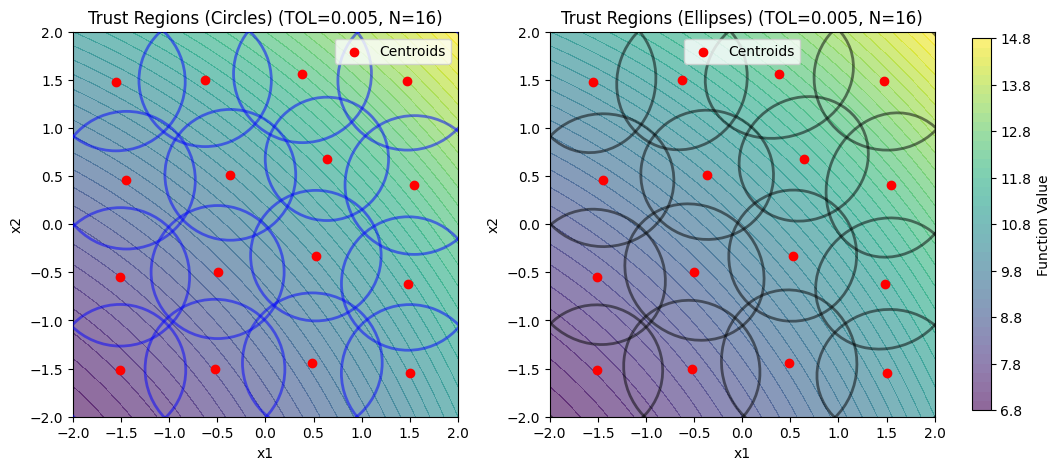

In [ ]:
surrogate = NearODESurrogate(version="v2")
TOL = 0.005
surrogate.train(
    X_train,
    f_fn=quadratic,
    g_fn=quadratic_grad,
    TOL=TOL,
    ERROR_METRIC="Linf-global",
    NUM_INITIAL_CLUSTERS=16,
)

x1 = np.linspace(DOMAIN[0], DOMAIN[1], 100)
x2 = np.linspace(DOMAIN[0], DOMAIN[1], 100)
X, Y = np.meshgrid(x1, x2)
F = quadratic(np.vstack([X.ravel(), Y.ravel()]).T).reshape(X.shape)


mus = surrogate.X_src
radii = surrogate.trust_radii_src
Qs = surrogate.Qs_src
print("Min radius:", np.min(radii) if len(radii) > 0 else "No radii")
print("Max radius:", np.max(radii) if len(radii) > 0 else "No radii")

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for i in range(2):
    axs[i].contourf(X, Y, F, levels=50, cmap="viridis", alpha=0.6)
    axs[i].scatter(mus[:, 0], mus[:, 1], c="red", label="Centroids", zorder=5)

# Plot circles & ellipses on ax0 and ax1
for i in range(mus.shape[0]):
    mu = mus[i]
    radius = radii[i]
    Q = Qs[i]

    # Draw circle around mu with radius
    circle = Ellipse(
        xy=mu,
        width=2 * radius,
        height=2 * radius,
        angle=0,
        edgecolor="blue",
        facecolor="none",
        linestyle="-",
        alpha=0.5,
        linewidth=2,
        zorder=3,
    )

    axs[0].add_patch(circle)

    # Plot ellipse
    w, V = np.linalg.eigh(Q)
    order = np.argsort(w)[::-1]
    w = w[order]
    V = V[:, order]
    angle = np.degrees(np.arctan2(V[1, 0], V[0, 0]))
    ellipse = Ellipse(
        xy=mu,
        width=2 / np.sqrt(w[0]),
        height=2 / np.sqrt(w[1]),
        angle=angle,
        edgecolor="black",
        facecolor="none",
        linestyle="-",
        alpha=0.5,
        linewidth=2,
        zorder=4,
    )
    axs[1].add_patch(ellipse)

# Format ax0
axs[0].set_title(f"Trust Regions (Circles) (TOL={TOL}, N={mus.shape[0]})")
axs[1].set_title(f"Trust Regions (Ellipses) (TOL={TOL}, N={mus.shape[0]})")

for i in range(2):
    axs[i].set_xlabel("x1")
    axs[i].set_ylabel("x2")
    axs[i].set_xlim(DOMAIN)
    axs[i].set_ylim(DOMAIN)
    axs[i].set_aspect("equal", adjustable="box")
    axs[i].legend()

cbar = fig.colorbar(
    axs[0].collections[0], ax=axs, orientation="vertical", fraction=0.02, pad=0.04
)
cbar.set_label("Function Value")

In [ ]:
DOMAIN = [-2, 2]
N_train = 200_000
np.random.seed(2)
X_train = np.random.uniform(DOMAIN[0], DOMAIN[1], size=(N_train, 2))

Min radius: 0.15241501512278197
Max radius: 0.6286074429437843


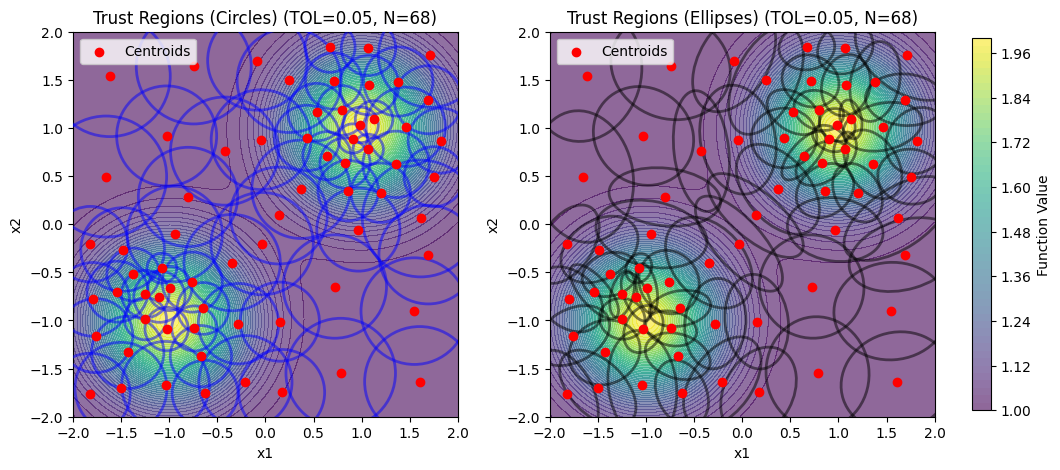

In [ ]:
surrogate = NearODESurrogate(version="v2")
TOL = 0.05
sf_g_fn = partial(shifted_gaussians, centers=CENTERS_2D)
sf_g_g_fn = partial(shifted_gaussians_grad, centers=CENTERS_2D)
surrogate.train(
    X_train,
    f_fn=sf_g_fn,
    g_fn=sf_g_g_fn,
    TOL=TOL,
    ERROR_METRIC="Linf-global",
    NUM_INITIAL_CLUSTERS=25,
)

x1 = np.linspace(DOMAIN[0], DOMAIN[1], 100)
x2 = np.linspace(DOMAIN[0], DOMAIN[1], 100)
X, Y = np.meshgrid(x1, x2)
F = sf_g_fn(np.vstack([X.ravel(), Y.ravel()]).T).reshape(X.shape)

mus = surrogate.X_src
radii = surrogate.trust_radii_src
Qs = surrogate.Qs_src
print("Min radius:", np.min(radii) if len(radii) > 0 else "No radii")
print("Max radius:", np.max(radii) if len(radii) > 0 else "No radii")

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for i in range(2):
    axs[i].contourf(X, Y, F, levels=50, cmap="viridis", alpha=0.6)
    axs[i].scatter(mus[:, 0], mus[:, 1], c="red", label="Centroids", zorder=5)

# Plot circles & ellipses on ax0 and ax1
for i in range(mus.shape[0]):
    mu = mus[i]
    radius = radii[i]
    Q = Qs[i]

    # Draw circle around mu with radius
    circle = Ellipse(
        xy=mu,
        width=2 * radius,
        height=2 * radius,
        angle=0,
        edgecolor="blue",
        facecolor="none",
        linestyle="-",
        alpha=0.5,
        linewidth=2,
        zorder=3,
    )

    axs[0].add_patch(circle)

    # Plot ellipse
    w, V = np.linalg.eigh(Q)
    order = np.argsort(w)[::-1]
    w = w[order]
    V = V[:, order]
    angle = np.degrees(np.arctan2(V[1, 0], V[0, 0]))
    ellipse = Ellipse(
        xy=mu,
        width=2 / np.sqrt(w[0]),
        height=2 / np.sqrt(w[1]),
        angle=angle,
        edgecolor="black",
        facecolor="none",
        linestyle="-",
        alpha=0.5,
        linewidth=2,
        zorder=4,
    )
    axs[1].add_patch(ellipse)

# Format ax0
axs[0].set_title(f"Trust Regions (Circles) (TOL={TOL}, N={mus.shape[0]})")
axs[1].set_title(f"Trust Regions (Ellipses) (TOL={TOL}, N={mus.shape[0]})")

for i in range(2):
    axs[i].set_xlabel("x1")
    axs[i].set_ylabel("x2")
    axs[i].set_xlim(DOMAIN)
    axs[i].set_ylim(DOMAIN)
    axs[i].set_aspect("equal", adjustable="box")
    axs[i].legend()

cbar = fig.colorbar(
    axs[0].collections[0], ax=axs, orientation="vertical", fraction=0.02, pad=0.04
)
cbar.set_label("Function Value")

Min radius: 0.06611452173298016
Max radius: 0.3230628570535334
Number of trust regions: 126


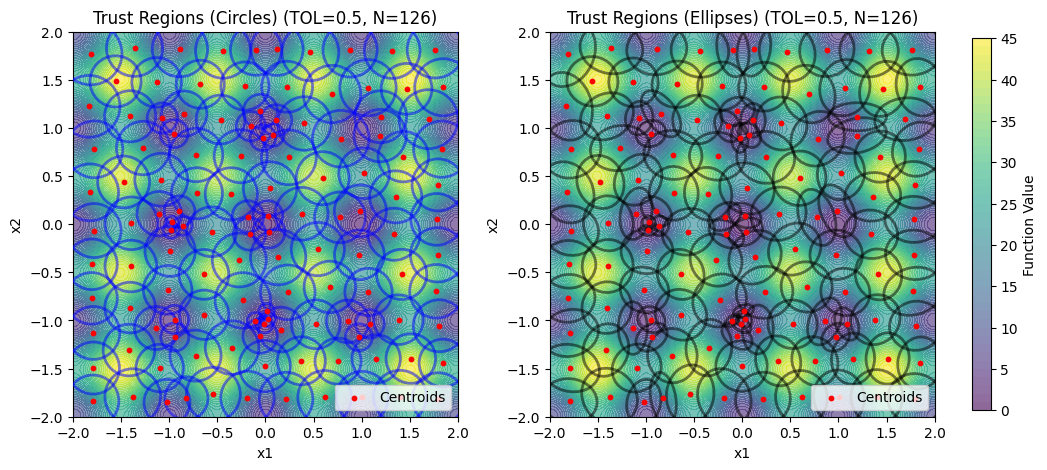

In [ ]:
surrogate = NearODESurrogate(version="v2")
TOL = 0.5
surrogate.train(
    X_train,
    f_fn=rastrigin,
    g_fn=rastrigin_grad,
    TOL=TOL,
    ERROR_METRIC="Linf-local",
    NUM_INITIAL_CLUSTERS=100,
)

x1 = np.linspace(DOMAIN[0], DOMAIN[1], 100)
x2 = np.linspace(DOMAIN[0], DOMAIN[1], 100)
X, Y = np.meshgrid(x1, x2)
F = rastrigin(np.vstack([X.ravel(), Y.ravel()]).T).reshape(X.shape)
mus = surrogate.X_src
radii = surrogate.trust_radii_src
Qs = surrogate.Qs_src
print("Min radius:", np.min(radii) if len(radii) > 0 else "No radii")
print("Max radius:", np.max(radii) if len(radii) > 0 else "No radii")
print("Number of trust regions:", mus.shape[0])

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for i in range(2):
    axs[i].contourf(X, Y, F, levels=50, cmap="viridis", alpha=0.6)
    axs[i].scatter(mus[:, 0], mus[:, 1], c="red", label="Centroids", zorder=5, s=10)

# Plot circles & ellipses on ax0 and ax1
for i in range(mus.shape[0]):
    mu = mus[i]
    radius = radii[i]
    Q = Qs[i]

    # Draw circle around mu with radius
    circle = Ellipse(
        xy=mu,
        width=2 * radius,
        height=2 * radius,
        angle=0,
        edgecolor="blue",
        facecolor="none",
        linestyle="-",
        alpha=0.5,
        linewidth=2,
        zorder=3,
    )

    axs[0].add_patch(circle)

    # Plot ellipse
    w, V = np.linalg.eigh(Q)
    order = np.argsort(w)[::-1]
    w = w[order]
    V = V[:, order]
    angle = np.degrees(np.arctan2(V[1, 0], V[0, 0]))
    ellipse = Ellipse(
        xy=mu,
        width=2 / np.sqrt(w[0]),
        height=2 / np.sqrt(w[1]),
        angle=angle,
        edgecolor="black",
        facecolor="none",
        linestyle="-",
        alpha=0.5,
        linewidth=2,
        zorder=4,
    )
    axs[1].add_patch(ellipse)

# Format ax0
axs[0].set_title(f"Trust Regions (Circles) (TOL={TOL}, N={mus.shape[0]})")
axs[1].set_title(f"Trust Regions (Ellipses) (TOL={TOL}, N={mus.shape[0]})")

for i in range(2):
    axs[i].set_xlabel("x1")
    axs[i].set_ylabel("x2")
    axs[i].set_xlim(DOMAIN)
    axs[i].set_ylim(DOMAIN)
    axs[i].set_aspect("equal", adjustable="box")
    axs[i].legend()

cbar = fig.colorbar(
    axs[0].collections[0], ax=axs, orientation="vertical", fraction=0.02, pad=0.04
)
cbar.set_label("Function Value")

Min radius: 0.04326963128442731
Max radius: 0.590179391867971
Number of trust regions: 303


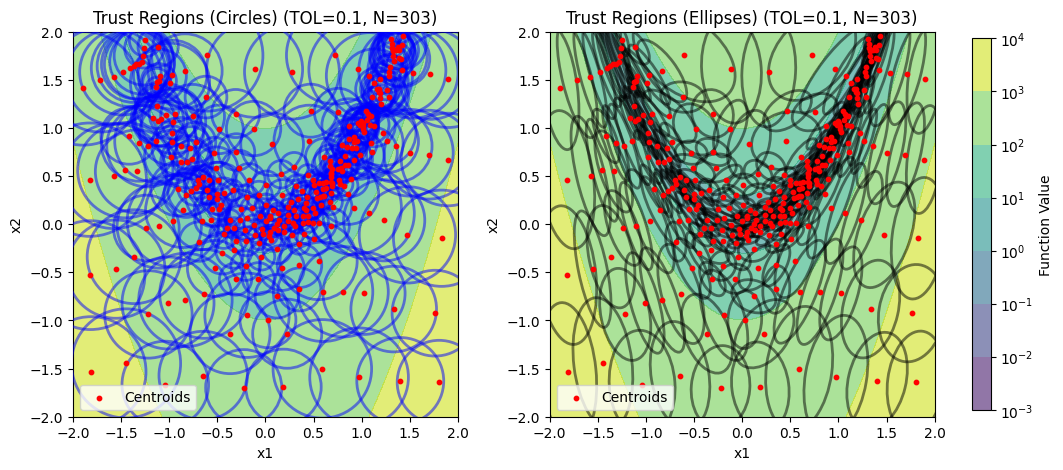

In [18]:
surrogate = NearODESurrogate(version="v2")
TOL = 0.1
surrogate.train(
    X_train,
    f_fn=rosenbrock,
    g_fn=rosenbrock_grad,
    TOL=TOL,
    ERROR_METRIC="Linf-local",
    NUM_INITIAL_CLUSTERS=25,
)

x1 = np.linspace(DOMAIN[0], DOMAIN[1], 100)
x2 = np.linspace(DOMAIN[0], DOMAIN[1], 100)
X, Y = np.meshgrid(x1, x2)
F = rosenbrock(np.vstack([X.ravel(), Y.ravel()]).T).reshape(X.shape)
mus = surrogate.X_src
radii = surrogate.trust_radii_src
Qs = surrogate.Qs_src
print("Min radius:", np.min(radii) if len(radii) > 0 else "No radii")
print("Max radius:", np.max(radii) if len(radii) > 0 else "No radii")
print("Number of trust regions:", mus.shape[0])

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for i in range(2):
    axs[i].contourf(X, Y, F, levels=50, cmap="viridis", alpha=0.6, norm=LogNorm())
    axs[i].scatter(mus[:, 0], mus[:, 1], c="red", label="Centroids", zorder=5, s=10)

# Plot circles & ellipses on ax0 and ax1
for i in range(mus.shape[0]):
    mu = mus[i]
    radius = radii[i]
    Q = Qs[i]

    # Draw circle around mu with radius
    circle = Ellipse(
        xy=mu,
        width=2 * radius,
        height=2 * radius,
        angle=0,
        edgecolor="blue",
        facecolor="none",
        linestyle="-",
        alpha=0.5,
        linewidth=2,
        zorder=3,
    )

    axs[0].add_patch(circle)

    # Plot ellipse
    w, V = np.linalg.eigh(Q)
    order = np.argsort(w)[::-1]
    w = w[order]
    V = V[:, order]
    angle = np.degrees(np.arctan2(V[1, 0], V[0, 0]))
    ellipse = Ellipse(
        xy=mu,
        width=2 / np.sqrt(w[0]),
        height=2 / np.sqrt(w[1]),
        angle=angle,
        edgecolor="black",
        facecolor="none",
        linestyle="-",
        alpha=0.5,
        linewidth=2,
        zorder=4,
    )
    axs[1].add_patch(ellipse)

# Format ax0
axs[0].set_title(f"Trust Regions (Circles) (TOL={TOL}, N={mus.shape[0]})")
axs[1].set_title(f"Trust Regions (Ellipses) (TOL={TOL}, N={mus.shape[0]})")

for i in range(2):
    axs[i].set_xlabel("x1")
    axs[i].set_ylabel("x2")
    axs[i].set_xlim(DOMAIN)
    axs[i].set_ylim(DOMAIN)
    axs[i].set_aspect("equal", adjustable="box")
    axs[i].legend()

cbar = fig.colorbar(
    axs[0].collections[0], ax=axs, orientation="vertical", fraction=0.02, pad=0.04
)
cbar.set_label("Function Value")